<a href="https://colab.research.google.com/github/vishwakumar1311/MiniGPT/blob/main/GPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import pandas
import matplotlib.pyplot as plt
import random

# Checking for GPU availability and set the device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [ ]:
text = open("/content/drive/MyDrive/input.txt").read()
print(len(text))

1115394


In [ ]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [ ]:
stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for i,ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

print(encode("Hello Eve"))
print(decode(encode("Hello Eve")))

[20, 43, 50, 50, 53, 1, 17, 60, 43]
Hello Eve


In [ ]:
data = torch.tensor(encode(text), dtype = torch.long)
print(data[:100])

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])


In [ ]:
#splitting the dataset
n = int(0.9*len(data))
train_data = data[:n]
val_data = data[n:]

In [ ]:
# Init Values
n_embd=90
eval_iters = 200

In [ ]:
torch.manual_seed(1337)
block_size = 128
batch_size =16
def get_batch(split):
  data = train_data if split=='train' else val_data
  ix = torch.randint(len(data)-block_size,(batch_size,))
  x = torch.stack([data[i:i+block_size] for i in ix])
  y = torch.stack([data[i+1:i+block_size+1] for i in ix])
  # Move data to the selected device
  x, y = x.to(device), y.to(device)
  return x,y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [ ]:
#multi head self attention
class Head(nn.Module):
  def __init__(self,head_size):
    super().__init__()
    self.key = nn.Linear(n_embd,head_size,bias=False)
    self.query = nn.Linear(n_embd,head_size,bias=False)
    self.value = nn.Linear(n_embd,head_size,bias=False)
    self.tril = torch.tril(torch.ones(block_size,block_size)).to(device) # Move tril to the device
    self.head_size = head_size
  def forward(self,x):
    B,T,C = x.shape
    k = self.key(x)
    q = self.query(x)
    v = self.value(x)
    wei = q @ k.mT * self.head_size**-0.5
    wei = wei.masked_fill(self.tril[:T,:T]==0,float('-inf'))
    wei = F.softmax(wei,dim=-1)
    out = wei @ v
    return out

class MultiHeadAttention(nn.Module):
  def __init__(self,num_heads,head_size):
    super().__init__()
    self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
    self.proj = nn.Linear(n_embd,n_embd)
  def forward(self,x):
    out = torch.cat([h(x) for h in self.heads],dim=-1)
    out = self.proj(out)
    return out

class FeedForward(nn.Module):
  def __init__(self,n_embd) -> None:
    super().__init__()
    self.net = nn.Sequential(
        nn.Linear(n_embd,4*n_embd),
        nn.GELU(),
        nn.Linear(4*n_embd,n_embd)
    )
  def forward(self,x):
    return self.net(x)

class layerNorm(nn.Module):
  def __init__(self,n_embd,eps=1e-5,momentum=0.1) -> None:
    super().__init__()
    self.eps = eps
    self.momentum = momentum
    self.gamma = nn.Parameter(torch.ones(n_embd))
    self.beta = nn.Parameter(torch.zeros(n_embd))
  def forward(self,x):
    xmean = x.mean(2,keepdim=True)
    xvar = x.var(2,keepdim=True)
    xhat = (x-xmean)/torch.sqrt(xvar+self.eps)
    self.out = self.gamma * xhat + self.beta
    return self.out

class Embeddings(nn.Module):
  def __init__(self,n_embd,vocab_size) -> None:
    super().__init__()
    self.token_embedding_table = nn.Embedding(vocab_size,n_embd)
    self.position_embedding_table = nn.Embedding(block_size,n_embd)
  def forward(self,idx):
    B,T = idx.shape
    self.T = T
    self.idx = idx
    # Ensure position embedding table indices are on the correct device
    position_indices = torch.arange(T, device=device)
    return self.token_embedding_table(idx)+self.position_embedding_table(position_indices)
  def __str__(self) -> str:
    return f"token_emb{self.token_embedding_table(self.idx).shape}\nposition_emb{self.position_embedding_table(torch.arange(self.T)).shape}"

In [ ]:
class Block(nn.Module):
  def __init__(self,n_embd,num_heads) -> None:
    super().__init__()
    head_size = n_embd//num_heads
    self.sa = MultiHeadAttention(num_heads,head_size)
    self.ffwd = FeedForward(n_embd)
    self.ln1 = layerNorm(n_embd)
    self.ln2 = layerNorm(n_embd)
  def forward(self,x):
    x = x+self.sa(self.ln1(x))
    x = x+self.ffwd(self.ln2(x))
    return x

In [ ]:
class GPT(nn.Module):
  def __init__(self,n_embd,vocab_size,num_heads,num_blocks):
    super().__init__()
    self.embedding = Embeddings(n_embd,vocab_size)
    self.blocks = nn.Sequential(*[Block(n_embd,num_heads) for _ in range(num_blocks)])
    self.ln = layerNorm(n_embd)
    self.lm_head = nn.Linear(n_embd,vocab_size)
    self.apply(self._init_weights)

  def _init_weights(self,module):
    if isinstance(module,nn.Linear):
      torch.nn.init.normal_(module.weight,mean=0.0,std=0.02)
      if module.bias is not None:
        torch.nn.init.zeros_(module.bias)
    elif isinstance(module,nn.Embedding):
      torch.nn.init.normal_(module.weight,mean=0.0,std=0.02)

  def forward(self,idx,targets=None):
    B,T = idx.shape
    x = self.embedding(idx)
    x = self.blocks(x)
    x = self.ln(x)
    logits = self.lm_head(x) #B,T,C --> B,T,Vocab_size
    if targets is None:
      loss = None
    else:
      B,T,C = logits.shape
      logits = logits.view(B*T,C)
      targets = targets.view(B*T)
      loss = F.cross_entropy(logits,targets)
    return logits,loss

  @torch.no_grad()
  def generate(self, idx, max_new_tokens):
      for _ in range(max_new_tokens):
          idx_cond = idx[:, -block_size:]
          logits, loss = self(idx_cond)
          logits = logits[:, -1, :] #(B, C)
          probs = F.softmax(logits, dim=-1) # (B, C)
          idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
          idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
      return idx

In [ ]:
learning_rate = 1e-3
loop=11000
model = GPT(n_embd=n_embd,vocab_size=vocab_size,num_heads=6,num_blocks=4)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(),lr=1e-3)
for i in range(loop):
  xb,yb = get_batch('train')
  logits,loss = model(xb,yb)
  optimizer.zero_grad(set_to_none=True)
  loss.backward()
  optimizer.step()
  if i%5000==0:
    print(f"loss:{estimate_loss()}")

loss:{'train': tensor(3.9250), 'val': tensor(3.9345)}
loss:{'train': tensor(1.4208), 'val': tensor(1.6470)}
loss:{'train': tensor(1.3211), 'val': tensor(1.5786)}


In [ ]:
import seaborn as sns
import numpy as np

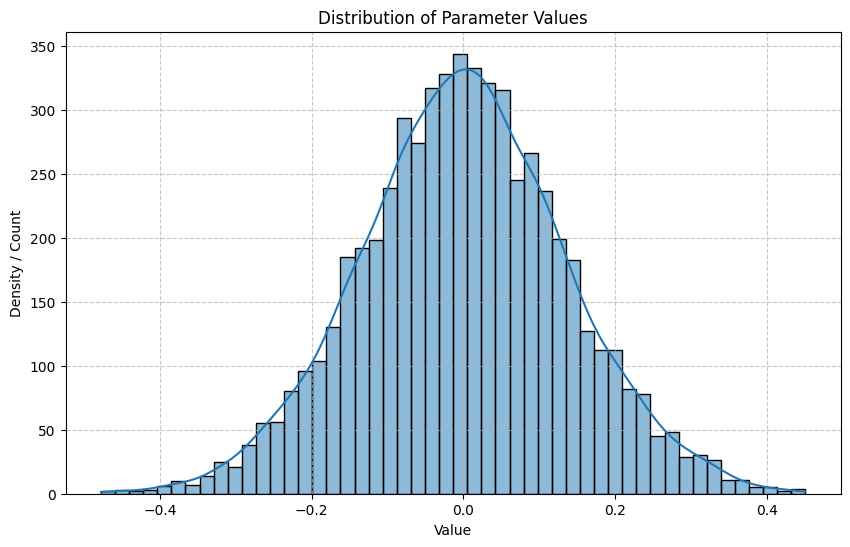

In [ ]:
param=model.parameters()
param=next(param)
param=param.detach().cpu().numpy().flatten()
plt.figure(figsize=(10, 6))
sns.histplot(param, kde=True, bins=50)
plt.title('Distribution of Parameter Values')
plt.xlabel('Value')
plt.ylabel('Density / Count')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
context = torch.zeros((1, 1), dtype=torch.long, device=device) # Starting with token 0 (newline) and move to device
generated_tokens = model.generate(context, max_new_tokens=500)
generated_text = decode(generated_tokens[0].tolist())
print(generated_text)



The purpose where eyes than I beseech you, Queen;
Sugges Mource i' the prize take all the world;
So we see meet thine ear tender in block-goose,
This in the Tower, and there abhorsed night.
This wicked as incession's peril lamentation
The leideren man's minery.

BUCKINGHALO:
By thou follow it famous let how!
Arm'd little to bear the day, Montague!

ARCHINARGIABET:
I would he love's standled with him from me;
And cavouring Rome, come villain who hath they
ne'er one that been much alliers as yet 
